# Component 3 — Fisheries Data Cleaning

This notebook creates traceable **interim** fisheries datasets. It standardizes representation and adds quality flags without overwriting raw files, dropping rows, removing outliers, combining years, or calculating CPUE. Environmental decoding and fisheries/environment integration remain later tasks.

## Scientific safeguards

- Raw workbooks remain immutable.
- Every staged record receives source-file, source-sheet, and source-row lineage.
- Original values remain available in their source columns; parsed values are added separately.
- Potential duplicates, invalid dates, invalid numerics, and suspicious coordinates are flagged, not deleted.
- Main-sheet choices are provisional configurations based on Data Audit 01 and must be confirmed with the provider.
- Catch units, effort comparability, CPUE, event date, and final spatial keys remain unresolved.

In [1]:
import importlib.util, subprocess, sys
required_packages = {
    'pandas': 'pandas>=2.0,<3', 'numpy': 'numpy>=1.24,<3',
    'openpyxl': 'openpyxl>=3.1,<4', 'pyarrow': 'pyarrow>=14,<22',
    'matplotlib': 'matplotlib>=3.7,<4',
}
missing_packages = [spec for module, spec in required_packages.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing_packages])
print('Cleaning notebook dependencies are available.')


Cleaning notebook dependencies are available.


In [2]:
from __future__ import annotations
import gc, json, os, re, sys
from pathlib import Path
from typing import Any
import matplotlib
if 'IPython' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_colwidth', 100)
NULL_TOKENS = {'', 'null', 'none', 'na', 'n/a', 'nan', '-'}
ROW_LIMIT_TEXT = os.getenv('FISHGUARD_C3_CLEANING_LIMIT', '').strip()
ROW_LIMIT = int(ROW_LIMIT_TEXT) if ROW_LIMIT_TEXT else None
RANDOM_SEED = 42


## 1. Configure Google Colab or local Windows paths

In [3]:
def find_component_root(start: Path) -> Path:
    anchors = [start.resolve(), *start.resolve().parents]
    for anchor in anchors:
        for candidate in [anchor, anchor / 'component - 3', anchor / 'J26-DS-350' / 'component - 3']:
            if (candidate / 'Notebooks').is_dir() and (candidate / 'src').is_dir():
                return candidate.resolve()
    raise FileNotFoundError(f'Could not locate Component 3 from {start.resolve()}')

RUNNING_IN_COLAB = 'google.colab' in sys.modules
if RUNNING_IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = Path('/content/drive/MyDrive/FishGuard-C3')
    COMPONENT_ROOT = None
    RAW_ROOT = DRIVE_ROOT / 'data' / 'raw'
    INTERIM_DIR = DRIVE_ROOT / 'data' / 'interim'
    CLEANING_OUTPUT_DIR = DRIVE_ROOT / 'outputs' / 'audit' / 'cleaning'
    FIGURE_DIR = DRIVE_ROOT / 'outputs' / 'figures' / 'data_cleaning'
else:
    COMPONENT_ROOT = find_component_root(Path.cwd())
    RAW_ROOT = Path(os.getenv('FISHGUARD_C3_RAW_DATA', str(COMPONENT_ROOT.parents[2] / 'component - 3' / 'data' / 'Raw'))).resolve()
    INTERIM_DIR = Path(os.getenv('FISHGUARD_C3_INTERIM_OUTPUT', str(COMPONENT_ROOT / 'data' / 'interim'))).resolve()
    CLEANING_OUTPUT_DIR = Path(os.getenv('FISHGUARD_C3_CLEANING_OUTPUT', str(COMPONENT_ROOT / 'outputs' / 'audit' / 'cleaning'))).resolve()
    FIGURE_DIR = Path(os.getenv('FISHGUARD_C3_FIGURE_OUTPUT', str(COMPONENT_ROOT / 'outputs' / 'figures' / 'data_cleaning'))).resolve()

FISHERIES_DIR = RAW_ROOT / 'Fisheries'
if not FISHERIES_DIR.is_dir(): raise FileNotFoundError(f'Missing fisheries directory: {FISHERIES_DIR}')
for directory in [INTERIM_DIR, CLEANING_OUTPUT_DIR, FIGURE_DIR]: directory.mkdir(parents=True, exist_ok=True)
print('Runtime:', 'Google Colab' if RUNNING_IN_COLAB else 'Local Windows')
print('Raw fisheries:', FISHERIES_DIR)
print('Interim output:', INTERIM_DIR)
print('Row limit:', ROW_LIMIT if ROW_LIMIT else 'full configured sheets')


Mounted at /content/drive
Runtime: Google Colab
Raw fisheries: /content/drive/MyDrive/FishGuard-C3/data/raw/Fisheries
Interim output: /content/drive/MyDrive/FishGuard-C3/data/interim
Row limit: full configured sheets


## 2. Provisional workbook configuration

Configuration is explicit so sheet choices and candidate fields are reviewable. The 2022 issue sheet is staged separately and is not treated as approved modelling data.

In [4]:
SOURCES = [
 {'year': 2017, 'file': '2017 Log Data.xlsx', 'sheet': 'Sheet1', 'role': 'candidate_observations'},
 {'year': 2018, 'file': '2018 Log data.xlsx', 'sheet': '2018 Log data', 'role': 'candidate_observations'},
 {'year': 2019, 'file': '2019 Log data.xlsx', 'sheet': 'Sheet1', 'role': 'candidate_observations'},
 {'year': 2020, 'file': '2020 Log Data.xlsx', 'sheet': 'Sheet5', 'role': 'candidate_observations'},
 {'year': 2021, 'file': '2021 LOGBOOK data final.xlsx', 'sheet': 'trip 2021', 'role': 'candidate_observations'},
 {'year': 2022, 'file': '2022 Log Data.xlsx', 'sheet': 'catch 2022_NARA_with  grid valu', 'role': 'candidate_observations'},
 {'year': 2022, 'file': '2022 Log Data.xlsx', 'sheet': 'values with issues', 'role': 'issue_records'},
 {'year': 2023, 'file': '2023 Log Data.xlsx', 'sheet': 'to NARA 2024_v1', 'role': 'candidate_observations'},
 {'year': 2024, 'file': '2024 Log Data.xlsx', 'sheet': 'Sheet1', 'role': 'candidate_observations'},
]
FULL_DATE_FIELDS = {'arrival_date', 'departure_date', 'rec_date', 'departure_date_time', 'arrival_date_time', 'date_time', 'dateandtime', 'enddateandtime'}
NUMERIC_PATTERNS = re.compile(r'(^kg$|weight|^qty$|amount|hook|mesh|depth|length|height|^y$|^m$|^d$|month|grid)', re.I)
COORDINATE_PATTERNS = re.compile(r'(lat|lon|long|start_n|start_e|end_n|end_e)', re.I)
display(pd.DataFrame(SOURCES))


,year,file,sheet,role
0,2017,2017 Log Data.xlsx,Sheet1,candidate_observations
1,2018,2018 Log data.xlsx,2018 Log data,candidate_observations
2,2019,2019 Log data.xlsx,Sheet1,candidate_observations
3,2020,2020 Log Data.xlsx,Sheet5,candidate_observations
4,2021,2021 LOGBOOK data final.xlsx,trip 2021,candidate_observations
5,2022,2022 Log Data.xlsx,catch 2022_NARA_with grid valu,candidate_observations
6,2022,2022 Log Data.xlsx,values with issues,issue_records
7,2023,2023 Log Data.xlsx,to NARA 2024_v1,candidate_observations
8,2024,2024 Log Data.xlsx,Sheet1,candidate_observations


## 3. Reusable cleaning functions

In [5]:
def normalise_column(value: Any, position: int) -> str:
    text = '' if value is None else str(value).strip().lower()
    text = re.sub(r'[^a-z0-9]+', '_', text).strip('_')
    return text or f'unnamed_{position:02d}'

def unique_columns(values) -> tuple[list[str], list[dict[str, Any]]]:
    counts, names, mapping = {}, [], []
    for position, original in enumerate(values, 1):
        base = normalise_column(original, position)
        counts[base] = counts.get(base, 0) + 1
        cleaned = base if counts[base] == 1 else f'{base}__{counts[base]}'
        names.append(cleaned)
        mapping.append({'column_position': position, 'original_header': original, 'staged_header': cleaned})
    return names, mapping

def standardise_text(series: pd.Series) -> tuple[pd.Series, int, int]:
    original = series.astype('string')
    stripped = original.str.strip().str.replace(r'\s+', ' ', regex=True)
    padded_count = int(((original.notna()) & (original != stripped)).sum())
    null_mask = stripped.str.lower().isin(NULL_TOKENS).fillna(False)
    return stripped.mask(null_mask, pd.NA), int(null_mask.sum()), padded_count

def parse_date_candidate(series: pd.Series) -> tuple[pd.Series, pd.Series]:
    parsed = pd.to_datetime(series, errors='coerce', dayfirst=True, format='mixed')
    supplied = series.notna() & series.astype('string').str.strip().ne('')
    return parsed, supplied & parsed.isna()

def parse_numeric_candidate(series: pd.Series) -> tuple[pd.Series, pd.Series]:
    parsed = pd.to_numeric(series, errors='coerce')
    supplied = series.notna() & series.astype('string').str.strip().ne('')
    return parsed, supplied & parsed.isna()

def suspicious_coordinate(series: pd.Series, field: str) -> pd.Series:
    numeric = pd.to_numeric(series, errors='coerce')
    if re.search(r'lat|start_n|end_n', field): return numeric.notna() & ~numeric.between(-90, 90)
    if re.search(r'lon|long|start_e|end_e', field): return numeric.notna() & ~numeric.between(-180, 180)
    return pd.Series(False, index=series.index)


## 4. Stage each configured sheet

Workbooks are processed and released one at a time to limit memory use. Parquet preserves typed columns and is substantially smaller than Excel.

In [6]:
summary_records, schema_records, output_records = [], [], []
for source in SOURCES:
    input_path = FISHERIES_DIR / source['file']
    if not input_path.is_file(): raise FileNotFoundError(input_path)
    print(f"Reading {source['file']} :: {source['sheet']}")
    frame = pd.read_excel(input_path, sheet_name=source['sheet'], nrows=ROW_LIMIT, engine='openpyxl')
    original_columns = list(frame.columns)
    staged_columns, mapping = unique_columns(original_columns)
    frame.columns = staged_columns
    for item in mapping:
        item.update({'year_label': source['year'], 'source_file': source['file'], 'source_sheet': source['sheet'], 'source_role': source['role']})
    schema_records.extend(mapping)

    frame.insert(0, 'source_row_number', np.arange(2, len(frame) + 2, dtype='int64'))
    frame.insert(0, 'source_role', source['role'])
    frame.insert(0, 'source_sheet', source['sheet'])
    frame.insert(0, 'source_file', source['file'])
    frame.insert(0, 'source_year_label', source['year'])

    placeholder_count = padded_count = non_numeric_count = invalid_date_count = suspicious_coordinate_count = 0
    data_columns = [column for column in frame.columns if not column.startswith('source_')]
    for column in data_columns:
        if pd.api.types.is_object_dtype(frame[column]) or pd.api.types.is_string_dtype(frame[column]):
            frame[column], placeholders, padded = standardise_text(frame[column])
            placeholder_count += placeholders; padded_count += padded
        base = column.split('__')[0]
        if base in FULL_DATE_FIELDS:
            parsed, invalid = parse_date_candidate(frame[column])
            frame[f'{column}__parsed'] = parsed
            frame[f'{column}__invalid_flag'] = invalid
            invalid_date_count += int(invalid.sum())
        if (NUMERIC_PATTERNS.search(base) or COORDINATE_PATTERNS.search(base)) and base not in FULL_DATE_FIELDS:
            parsed, invalid = parse_numeric_candidate(frame[column])
            frame[f'{column}__numeric'] = parsed
            frame[f'{column}__non_numeric_flag'] = invalid
            non_numeric_count += int(invalid.sum())
        if COORDINATE_PATTERNS.search(base):
            flag = suspicious_coordinate(frame[column], base)
            frame[f'{column}__range_flag'] = flag
            suspicious_coordinate_count += int(flag.sum())

    comparison_columns = [column for column in data_columns if column in frame.columns]
    frame['duplicate_row_flag'] = frame.duplicated(subset=comparison_columns, keep=False)
    frame['any_quality_flag'] = frame.filter(regex=r'(_flag$|__range_flag$)').any(axis=1) | frame['duplicate_row_flag']

    suffix = 'issues' if source['role'] == 'issue_records' else 'staged'
    output_name = f"fisheries_{source['year']}_{suffix}.parquet"
    output_path = INTERIM_DIR / output_name
    frame.to_parquet(output_path, index=False)
    summary_records.append({'year_label': source['year'], 'source_file': source['file'], 'source_sheet': source['sheet'],
        'source_role': source['role'], 'rows_read': len(frame), 'staged_columns': len(frame.columns),
        'empty_cells_after_standardisation': int(frame[data_columns].isna().sum().sum()),
        'placeholder_tokens_converted': placeholder_count, 'padded_text_values_standardised': padded_count,
        'non_numeric_candidate_flags': non_numeric_count, 'invalid_date_flags': invalid_date_count,
        'suspicious_coordinate_flags': suspicious_coordinate_count,
        'duplicate_rows_flagged': int(frame['duplicate_row_flag'].sum()),
        'rows_with_any_quality_flag': int(frame['any_quality_flag'].sum()), 'output_file': output_name})
    output_records.append({'file': output_name, 'rows': len(frame), 'size_mb': round(output_path.stat().st_size / 1024**2, 2)})
    del frame; gc.collect()

cleaning_summary = pd.DataFrame(summary_records)
schema_mapping = pd.DataFrame(schema_records)
output_inventory = pd.DataFrame(output_records)
display(cleaning_summary)
display(output_inventory)


Reading 2017 Log Data.xlsx :: Sheet1
Reading 2018 Log data.xlsx :: 2018 Log data
Reading 2019 Log data.xlsx :: Sheet1
Reading 2020 Log Data.xlsx :: Sheet5
Reading 2021 LOGBOOK data final.xlsx :: trip 2021
Reading 2022 Log Data.xlsx :: catch 2022_NARA_with  grid valu
Reading 2022 Log Data.xlsx :: values with issues
Reading 2023 Log Data.xlsx :: to NARA 2024_v1
Reading 2024 Log Data.xlsx :: Sheet1


,year_label,source_file,source_sheet,source_role,rows_read,staged_columns,empty_cells_after_standardisation,placeholder_tokens_converted,padded_text_values_standardised,non_numeric_candidate_flags,invalid_date_flags,suspicious_coordinate_flags,duplicate_rows_flagged,rows_with_any_quality_flag,output_file
0,2017,2017 Log Data.xlsx,Sheet1,candidate_observations,604311,50,2485089,131865,5868937,1208624,935,0,78825,604311,fisheries_2017_staged.parquet
1,2018,2018 Log data.xlsx,2018 Log data,candidate_observations,363234,94,2116951,317,1453458,1625606,162,111,5658,363234,fisheries_2018_staged.parquet
2,2019,2019 Log data.xlsx,Sheet1,candidate_observations,408747,72,4198980,306,409006,817552,243,0,0,408747,fisheries_2019_staged.parquet
3,2020,2020 Log Data.xlsx,Sheet5,candidate_observations,284626,40,19482,0,30057,0,0,65140,61105,77657,fisheries_2020_staged.parquet
4,2021,2021 LOGBOOK data final.xlsx,trip 2021,candidate_observations,280619,92,2382369,2,597653,584598,86252,150733,2279,280619,fisheries_2021_staged.parquet
5,2022,2022 Log Data.xlsx,catch 2022_NARA_with grid valu,candidate_observations,158819,45,731,0,27412,158883,86343,296,52798,158819,fisheries_2022_staged.parquet
6,2022,2022 Log Data.xlsx,values with issues,issue_records,28781,39,1153,0,3859,28781,0,0,15622,28781,fisheries_2022_issues.parquet
7,2023,2023 Log Data.xlsx,to NARA 2024_v1,candidate_observations,271412,37,34431,0,13023,0,22165,14,92448,102976,fisheries_2023_staged.parquet
8,2024,2024 Log Data.xlsx,Sheet1,candidate_observations,230395,35,2256,0,12680,0,0,0,50,50,fisheries_2024_staged.parquet


,file,rows,size_mb
0,fisheries_2017_staged.parquet,604311,15.71
1,fisheries_2018_staged.parquet,363234,10.93
2,fisheries_2019_staged.parquet,408747,9.04
3,fisheries_2020_staged.parquet,284626,8.16
4,fisheries_2021_staged.parquet,280619,15.43
5,fisheries_2022_staged.parquet,158819,4.74
6,fisheries_2022_issues.parquet,28781,0.62
7,fisheries_2023_staged.parquet,271412,6.48
8,fisheries_2024_staged.parquet,230395,5.52


## 5. Reconciliation checks

In [7]:
assert len(cleaning_summary) == len(SOURCES)
assert cleaning_summary['rows_read'].gt(0).all()
assert output_inventory['rows'].sum() == cleaning_summary['rows_read'].sum()
assert output_inventory['file'].is_unique
assert all((INTERIM_DIR / name).is_file() for name in output_inventory['file'])
print('Reconciliation passed: every configured sheet produced one non-empty staged artifact.')
print('No source workbook was overwritten and no row was intentionally dropped.')


Reconciliation passed: every configured sheet produced one non-empty staged artifact.
No source workbook was overwritten and no row was intentionally dropped.


## 6. Data-quality visualizations

These plots support cleaning transparency and viva discussion. They are not biological or predictive findings.

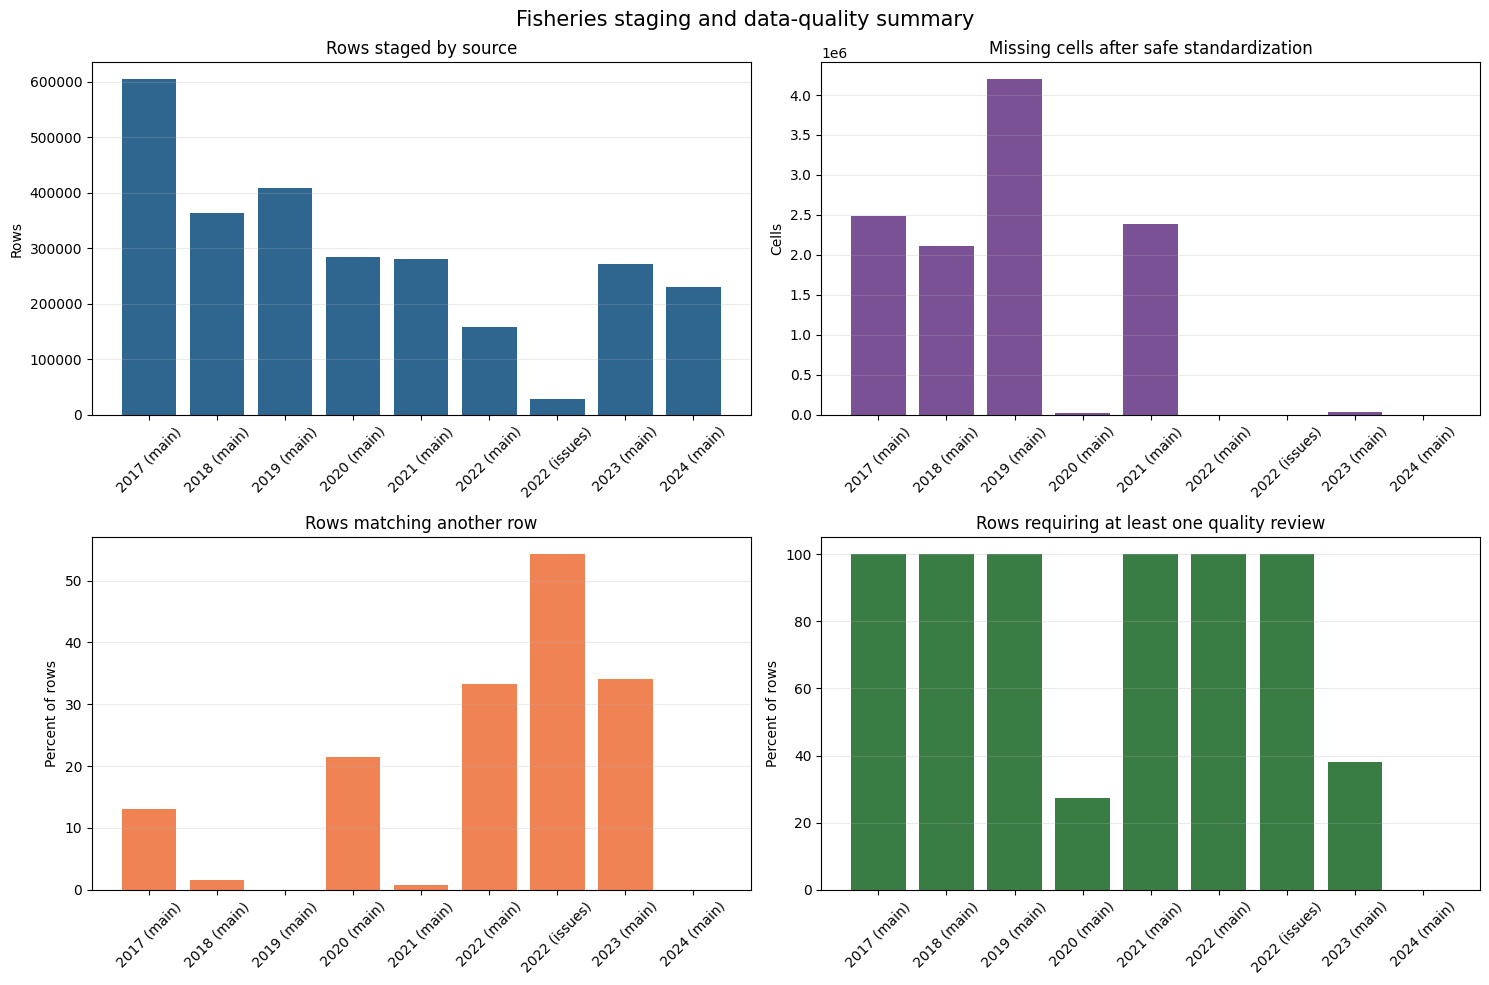

Saved: /content/drive/MyDrive/FishGuard-C3/outputs/figures/data_cleaning/cleaning_quality_summary.png


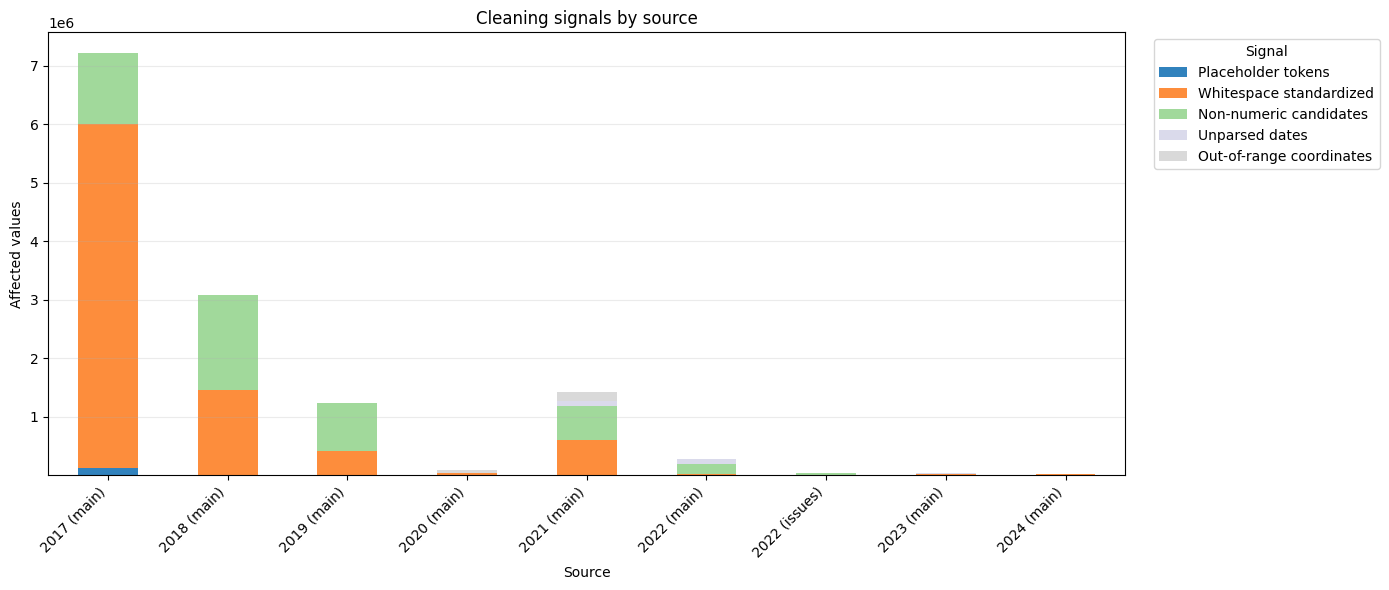

Saved: /content/drive/MyDrive/FishGuard-C3/outputs/figures/data_cleaning/cleaning_signal_counts.png


In [8]:
plot_data = cleaning_summary.copy()
plot_data['source_label'] = plot_data.apply(lambda r: f"{r['year_label']} ({'issues' if r['source_role']=='issue_records' else 'main'})", axis=1)
plot_data['duplicate_rate_pct'] = 100 * plot_data['duplicate_rows_flagged'] / plot_data['rows_read']
plot_data['quality_flag_rate_pct'] = 100 * plot_data['rows_with_any_quality_flag'] / plot_data['rows_read']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0,0].bar(plot_data['source_label'], plot_data['rows_read'], color='#2f6690')
axes[0,0].set_title('Rows staged by source'); axes[0,0].set_ylabel('Rows')
axes[0,1].bar(plot_data['source_label'], plot_data['empty_cells_after_standardisation'], color='#7a5195')
axes[0,1].set_title('Missing cells after safe standardization'); axes[0,1].set_ylabel('Cells')
axes[1,0].bar(plot_data['source_label'], plot_data['duplicate_rate_pct'], color='#ef8354')
axes[1,0].set_title('Rows matching another row'); axes[1,0].set_ylabel('Percent of rows')
axes[1,1].bar(plot_data['source_label'], plot_data['quality_flag_rate_pct'], color='#3a7d44')
axes[1,1].set_title('Rows requiring at least one quality review'); axes[1,1].set_ylabel('Percent of rows')
for axis in axes.flat:
    axis.tick_params(axis='x', rotation=45); axis.grid(axis='y', alpha=0.25)
fig.suptitle('Fisheries staging and data-quality summary', fontsize=15)
fig.tight_layout(); figure_path = FIGURE_DIR / 'cleaning_quality_summary.png'
fig.savefig(figure_path, dpi=200, bbox_inches='tight'); plt.show()
print('Saved:', figure_path)

issue_columns = ['placeholder_tokens_converted', 'padded_text_values_standardised',
                 'non_numeric_candidate_flags', 'invalid_date_flags', 'suspicious_coordinate_flags']
issue_labels = ['Placeholder tokens', 'Whitespace standardized', 'Non-numeric candidates',
                'Unparsed dates', 'Out-of-range coordinates']
issue_data = plot_data.set_index('source_label')[issue_columns]
issue_data.columns = issue_labels
ax = issue_data.plot(kind='bar', stacked=True, figsize=(14, 6), colormap='tab20c')
ax.set_title('Cleaning signals by source'); ax.set_xlabel('Source'); ax.set_ylabel('Affected values')
ax.grid(axis='y', alpha=0.25); ax.legend(title='Signal', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
issue_figure_path = FIGURE_DIR / 'cleaning_signal_counts.png'
plt.savefig(issue_figure_path, dpi=200, bbox_inches='tight'); plt.show()
print('Saved:', issue_figure_path)


## 7. Save cleaning evidence and manifest

In [9]:
cleaning_summary.to_csv(CLEANING_OUTPUT_DIR / 'cleaning_summary.csv', index=False)
schema_mapping.to_csv(CLEANING_OUTPUT_DIR / 'schema_mapping.csv', index=False)
output_inventory.to_csv(CLEANING_OUTPUT_DIR / 'interim_output_inventory.csv', index=False)
manifest = {'created_utc': pd.Timestamp.now(tz='UTC').isoformat(),
    'runtime': 'Google Colab' if RUNNING_IN_COLAB else 'Local Windows', 'row_limit': ROW_LIMIT,
    'raw_root': str(RAW_ROOT), 'interim_directory': str(INTERIM_DIR),
    'transformations': ['unique machine-safe headers', 'trim/collapse text whitespace',
        'convert explicit placeholder tokens to missing values', 'add parsed candidate date columns',
        'add parsed candidate numeric columns and non-numeric review flags', 'add coordinate range flags',
        'add duplicate and combined quality flags', 'preserve source lineage'],
    'non_actions': ['no raw overwrite', 'no row deletion', 'no outlier deletion', 'no year merging',
        'no CPUE calculation', 'no environmental integration'],
    'outputs': output_inventory.to_dict(orient='records')}
with (CLEANING_OUTPUT_DIR / 'cleaning_manifest.json').open('w', encoding='utf-8') as handle:
    json.dump(manifest, handle, indent=2, ensure_ascii=False)
print('Saved cleaning evidence to:', CLEANING_OUTPUT_DIR)


Saved cleaning evidence to: /content/drive/MyDrive/FishGuard-C3/outputs/audit/cleaning


## 8. Interpretation and next decision

This notebook produces year-specific staged files, not a combined modelling dataset. Review `cleaning_summary.csv`, `schema_mapping.csv`, the issue-specific 2022 artifact, and the quality plot before proceeding.

The next research task is to approve a cross-year semantic mapping: row definition, species field, catch field and unit, event date, spatial field, and usable effort measure. Only then should a later cleaning revision harmonize years and `03_data_integration.ipynb` align environmental data.

### Visualization roadmap

- This notebook: missingness, duplication, parsing, and cleaning-quality plots.
- `04_eda.ipynb`: catch/species distributions, temporal trends, seasonality, spatial patterns, and environmental series.
- `05_lag_analysis.ipynb`: lag correlations and delayed environmental relationships.
- Model notebooks: baseline comparison, validation errors, actual versus predicted values, and explainability.